# Predicción del riesgo de hipoglucemia asociado a la actividad física en personas con diabetes

## Dataset original: CGMacros

**CGMacros: A Scientific Dataset for Personalized Nutrition and Diet Monitoring**

*CGMacros: un conjunto de datos científicos para la nutrición personalizada y el seguimiento de la alimentación.*

CGMacros es un conjunto de datos de investigación que contiene registros de personas sin diabetes, con prediabetes y con diabetes tipo 2. Incluye mediciones continuas de glucosa, actividad física, alimentación y otras variables fisiológicas.

Su objetivo original es contribuir al estudio de las respuestas glucémicas individuales y su relación con la alimentación y otros factores cotidianos.

## Nuestro proyecto de Aprendizaje Automático

A partir de CGMacros, desarrollamos un proyecto para estudiar la relación entre la actividad física y la hipoglucemia en personas con diabetes.

Utilizamos los registros de glucosa para identificar la presencia o ausencia de hipoglucemia y variables relacionadas con la actividad física para desarrollar un **modelo de clasificación binaria**.

Primero exploramos los registros de un participante para conocer la estructura de los datos. Posteriormente, ampliamos el análisis al conjunto de participantes seleccionado para desarrollar y evaluar el modelo.

Pregunta del proyecto: ¿Es posible identificar el riesgo de hipoglucemia asociado a la actividad física mediante Aprendizaje Automático?

Cada fila que vemos no representa una persona diferente. Son mediciones sucesivas del mismo participante, tomadas aproximadamente minuto a minuto.

## Definición de hipoglucemia y actividad física

### Hipoglucemia

La hipoglucemia ocurre cuando la glucosa en sangre desciende por debajo de **70 miligramos por decilitro**.

En este trabajo se consideró un **episodio de hipoglucemia** cuando la glucosa permaneció por debajo de ese valor durante **al menos 15 minutos consecutivos**.

De esta manera se evita considerar como episodio una disminución aislada y muy breve de la glucosa.

### Actividad física

En el conjunto de datos CGMacros, la actividad física fue registrada mediante un **dispositivo Fitbit**.

Este dispositivo estima la intensidad de la actividad mediante una medida llamada **MET**, que permite comparar el esfuerzo realizado con el gasto energético del cuerpo en reposo.

Cuanto mayor es el valor de MET, mayor es la intensidad de la actividad.



Para facilitar su interpretación, la actividad se clasificó de la siguiente manera:

- **Actividad ligera:** menos de 3 MET. Por ejemplo, caminar lentamente o realizar tareas domésticas livianas.
- **Actividad moderada:** entre 3 y 5,9 MET. Por ejemplo, caminar a paso rápido o andar en bicicleta a ritmo tranquilo.
- **Actividad vigorosa:** 6 MET o más. Por ejemplo, correr, subir escaleras rápidamente o andar en bicicleta a ritmo intenso.

Para este trabajo se consideraron períodos de actividad física aquellos con una intensidad de **3 MET o más**, es decir, actividad moderada o vigorosa.

### Aclaración sobre los valores de MET

En CGMacros, los valores de MET registrados por Fitbit están almacenados multiplicados por 10.

Por este motivo, los dividimos por 10 para expresarlos en su valor real y facilitar su interpretación.

### Relación entre actividad física e hipoglucemia

Durante la actividad física, los músculos aumentan el consumo de glucosa para obtener energía. Además, el ejercicio puede aumentar la sensibilidad a la insulina, facilitando la entrada de glucosa desde la sangre hacia las células.

En una persona con diabetes, estos efectos pueden favorecer un descenso excesivo de la glucosa y aumentar el riesgo de hipoglucemia durante el ejercicio o después de haberlo realizado.

Sin embargo, la respuesta depende de diferentes factores, como la intensidad y duración del ejercicio, la glucosa previa, la alimentación y el tratamiento utilizado.

Por este motivo, en este proyecto se analiza la actividad física mediante los METs junto con la glucosa previa para estudiar su relación con la aparición posterior de hipoglucemia.

## Información de los participantes de CGMacros

El archivo `bio.csv` contiene información individual de los participantes del estudio, incluyendo características demográficas, antropométricas y resultados de laboratorio.

A diferencia de los archivos individuales de CGMacros, que contienen mediciones de glucosa y actividad física registradas a lo largo del tiempo, este archivo permite conocer las características de las personas que participaron en la investigación.


## Selección de los participantes para el análisis

Para desarrollar el modelo de Aprendizaje Automático se utilizarán datos de los participantes con diabetes incluidos en CGMacros.

Para identificar los participantes que serán incluidos en el análisis utilizaremos la información disponible en el archivo `bio.csv`.

Primero revisamos las variables disponibles y luego aplicamos el criterio de selección.

In [37]:
import pandas as pd
from pathlib import Path
import subprocess

repositorio = Path('/content/Parcial-de-Aprendizaje-Automatico')
if not repositorio.exists():
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/DanielRojas-creator/Parcial-de-Aprendizaje-Automatico.git', str(repositorio)], check=True)

bio = pd.read_csv(repositorio / 'data' / 'bio.csv')
bio.head()


,subject,Age,Gender,BMI,Body weight,Height,Self-identify,A1c PDL (Lab),Fasting GLU - PDL (Lab),Insulin,...,LDL (Cal),VLDL (Cal),Cho/HDL Ratio,Collection time PDL (Lab),#1 Contour Fingerstick GLU,Time (t),#2 Contour Fingerstick GLU,Time (t).1,#3 Contour Fingerstick GLU,Time (t).2
0,1,27,M,22.265239,133.8,65.0,Hispanic/Latino,5.4,91,2.5,...,130,13,2.9,11:06:00 AM,89,9:40,73,12:11,81,13:18
1,2,49,F,30.946742,169.2,62.0,Hispanic/Latino,5.5,93,14.8,...,78,12,2.0,7:38:00 AM,91,7:52,123,9:21,80,10:22
2,3,59,F,26.948690,157.0,64.0,Hispanic/Latino,6.5,118,17.4,...,90,31,2.6,7:25:00 AM,119,7:38,166,9:23,98,10:23
3,4,33,F,42.384279,262.6,66.0,Hispanic/Latino,5.5,105,19.4,...,164,60,5.8,7:20:00 AM,109,7:37,110,9:04,90,10:01
4,5,51,F,30.957534,172.0,62.5,Hispanic/Latino,6.6,144,12.9,...,157,78,7.1,7:45:00 AM,139,8:59,215,10:52,130,11:54


In [38]:
bio.columns.tolist()

['subject',
 'Age',
 'Gender',
 'BMI',
 'Body weight ',
 'Height ',
 'Self-identify ',
 'A1c PDL (Lab)',
 'Fasting GLU - PDL (Lab)',
 'Insulin ',
 'Triglycerides',
 'Cholesterol',
 'HDL',
 'Non HDL ',
 'LDL (Cal)',
 'VLDL (Cal)',
 'Cho/HDL Ratio',
 'Collection time PDL (Lab)',
 '#1 Contour Fingerstick GLU',
 'Time (t)',
 ' #2 Contour Fingerstick GLU',
 'Time (t).1',
 '#3 Contour Fingerstick GLU',
 'Time (t).2']

### Identificación de los participantes con diabetes

CGMacros incluye participantes sin diabetes, con prediabetes y con diabetes tipo 2.

Para este proyecto nos interesan los participantes con diabetes tipo 2. Según la documentación de CGMacros, este grupo corresponde a los participantes con un valor de HbA1c mayor de 6,4 %.

La HbA1c es un análisis de sangre que refleja el nivel promedio de glucosa de los últimos meses.

Por este motivo, utilizamos esta variable para seleccionar los participantes con diabetes tipo 2 que serán incluidos en nuestro análisis.

In [39]:
diabetes = bio[bio["A1c PDL (Lab)"] > 6.4]

In [40]:
diabetes[["subject", "A1c PDL (Lab)"]]

,subject,A1c PDL (Lab)
2,3,6.5
4,5,6.6
11,12,7.1
13,14,7.1
25,28,7.0
27,30,7.6
32,35,8.5
33,36,6.9
34,38,7.2
35,39,8.3


## Resultado de la selección

De acuerdo con la clasificación utilizada en el dataset CGMacros, se seleccionaron los participantes con un valor de HbA1c de laboratorio superior a 6,4 %.

Mediante este criterio se identificaron **14 participantes con diabetes tipo 2**, que constituyen la población de interés para el presente análisis.



## Acceso a los archivos de los participantes

Una vez identificados los 14 participantes con diabetes tipo 2, necesitamos localizar sus archivos individuales de CGMacros para acceder a sus registros de glucosa y actividad física.

Para ello, indicamos la ubicación de la carpeta donde se encuentran almacenados los datos y comprobamos que Python pueda acceder correctamente a ella.

In [41]:
from pathlib import Path

In [42]:
ruta_datos = repositorio / 'data' / 'CGMacros_14_CSV_GitHub'


In [43]:
archivos = sorted(ruta_datos.glob('CGMacros-*.csv'))
len(archivos)


14

Se localizaron los archivos individuales de los 14 participantes seleccionados en la carpeta `data/CGMacros_14_CSV_GitHub` del repositorio.


In [44]:
participantes_diabetes = diabetes["subject"].tolist()

participantes_diabetes

[3, 5, 12, 14, 28, 30, 35, 36, 38, 39, 42, 46, 47, 49]

## Análisis de los participantes seleccionados

A continuación se analizarán los registros de los participantes seleccionados para identificar episodios de hipoglucemia y estudiar la actividad física asociada.

### Carga de los datos de los 14 participantes

A partir de la lista obtenida previamente, cargamos los archivos individuales de los 14 participantes con diabetes tipo 2. Cada archivo contiene sus registros temporales de glucosa, actividad física y otras variables.

Estos datos serán utilizados para identificar las mediciones de glucosa inferiores a 70 mg/dL y posteriormente analizar los episodios de hipoglucemia.

In [9]:
datos_participantes = {}

for participante in participantes_diabetes:
    nombre = f'CGMacros-{participante:03d}'
    archivo = ruta_datos / f'{nombre}.csv'
    datos_participantes[nombre] = pd.read_csv(archivo)

len(datos_participantes)


14

## Identificación de episodios de hipoglucemia en los participantes

En cada uno de los 14 participantes analizamos los registros de glucosa para identificar episodios de hipoglucemia.

Consideramos como episodio de hipoglucemia un período en el que la glucosa permanece por debajo de 70 mg/dL durante al menos 15 minutos, de acuerdo con el criterio establecido previamente.

In [10]:
resultados_episodios = []

for nombre, datos in datos_participantes.items():

    datos["Timestamp"] = pd.to_datetime(datos["Timestamp"])
    hipo = datos[datos["Libre GL"] < 70].copy()

    if len(hipo) > 0:
        hipo["Diferencia_tiempo"] = hipo["Timestamp"].diff()

        hipo["Bloque"] = (
            hipo["Diferencia_tiempo"] > pd.Timedelta(minutes=1)
        ).cumsum() + 1

        bloques = hipo.groupby("Bloque").agg(
            Inicio=("Timestamp", "min"),
            Fin=("Timestamp", "max")
        )

        bloques["Duracion"] = bloques["Fin"] - bloques["Inicio"]

        episodios = (
            bloques["Duracion"] >= pd.Timedelta(minutes=15)
        ).sum()

    else:
        episodios = 0

    resultados_episodios.append({
        "Participante": nombre,
        "Episodios": episodios
    })

resumen_episodios = pd.DataFrame(resultados_episodios)

resumen_episodios

,Participante,Episodios
0,CGMacros-003,4
1,CGMacros-005,5
2,CGMacros-012,0
3,CGMacros-014,1
4,CGMacros-028,2
5,CGMacros-030,1
6,CGMacros-035,0
7,CGMacros-036,18
8,CGMacros-038,1
9,CGMacros-039,3


### Resultado de la identificación de episodios

Se identificaron episodios de hipoglucemia en varios de los participantes analizados, mientras que otros no presentaron episodios que cumplieran el criterio establecido.

A partir de estos episodios, el siguiente paso será analizar la actividad física registrada antes de su aparición.

### Registro individual de los episodios detectados

Para analizar la actividad física previa a cada episodio necesitamos conocer su momento de inicio y finalización.

Por este motivo, registramos individualmente los episodios identificados en los 14 participantes, conservando el participante al que pertenecen y las fechas y horas de inicio y fin.

In [11]:
episodios_detectados = []

for nombre, datos in datos_participantes.items():

    datos["Timestamp"] = pd.to_datetime(datos["Timestamp"])
    hipo = datos[datos["Libre GL"] < 70].copy()

    if len(hipo) > 0:
        hipo["Diferencia_tiempo"] = hipo["Timestamp"].diff()

        hipo["Bloque"] = (
            hipo["Diferencia_tiempo"] > pd.Timedelta(minutes=1)
        ).cumsum() + 1

        bloques = hipo.groupby("Bloque").agg(
            Inicio=("Timestamp", "min"),
            Fin=("Timestamp", "max")
        )

        bloques["Duracion"] = bloques["Fin"] - bloques["Inicio"]
        bloques = bloques[
            bloques["Duracion"] >= pd.Timedelta(minutes=15)
        ]

        for _, episodio in bloques.iterrows():
            episodios_detectados.append({
                "Participante": nombre,
                "Inicio": episodio["Inicio"],
                "Fin": episodio["Fin"]
            })

episodios_detectados = pd.DataFrame(episodios_detectados)

episodios_detectados

,Participante,Inicio,Fin
0,CGMacros-003,2020-03-11 15:50:00,2020-03-11 17:34:00
1,CGMacros-003,2020-03-12 04:17:00,2020-03-12 05:17:00
2,CGMacros-003,2020-03-12 13:04:00,2020-03-12 13:42:00
3,CGMacros-003,2020-03-17 12:14:00,2020-03-17 12:32:00
4,CGMacros-005,2020-08-17 13:52:00,2020-08-17 14:39:00
5,CGMacros-005,2020-08-18 00:43:00,2020-08-18 01:33:00
6,CGMacros-005,2020-08-18 02:19:00,2020-08-18 04:00:00
7,CGMacros-005,2020-08-18 04:35:00,2020-08-18 05:13:00
8,CGMacros-005,2020-08-19 04:43:00,2020-08-19 05:01:00
9,CGMacros-014,2023-05-17 02:47:00,2023-05-17 03:48:00


## Actividad física previa a los episodios de hipoglucemia

Para estudiar la posible relación entre actividad física e hipoglucemia, analizamos la hora anterior al inicio de cada episodio detectado.

Utilizamos los MET para representar la intensidad de la actividad física y contamos cuántos registros presentaron valores de 3 MET o más, correspondientes a actividad de intensidad moderada o superior.

In [12]:
actividad_previa = []

for _, episodio in episodios_detectados.iterrows():

    participante = episodio["Participante"]
    datos = datos_participantes[participante].copy()

    if "METs" not in datos.columns:
        continue

    datos["Timestamp"] = pd.to_datetime(datos["Timestamp"])
    datos["METs_reales"] = datos["METs"] / 10

    inicio = episodio["Inicio"]
    hora_antes = inicio - pd.Timedelta(hours=1)

    periodo = datos[
        (datos["Timestamp"] >= hora_antes) &
        (datos["Timestamp"] < inicio)
    ]

    registros_activos = (periodo["METs_reales"] >= 3).sum()

    actividad_previa.append({
        "Participante": participante,
        "Inicio_episodio": inicio,
        "Registros_>=3_MET": registros_activos
    })

actividad_previa = pd.DataFrame(actividad_previa)

actividad_previa

,Participante,Inicio_episodio,Registros_>=3_MET
0,CGMacros-003,2020-03-11 15:50:00,2
1,CGMacros-003,2020-03-12 04:17:00,1
2,CGMacros-003,2020-03-12 13:04:00,53
3,CGMacros-003,2020-03-17 12:14:00,28
4,CGMacros-005,2020-08-17 13:52:00,8
5,CGMacros-005,2020-08-18 00:43:00,0
6,CGMacros-005,2020-08-18 02:19:00,0
7,CGMacros-005,2020-08-18 04:35:00,0
8,CGMacros-005,2020-08-19 04:43:00,0
9,CGMacros-014,2023-05-17 02:47:00,0


## Análisis de la actividad física previa a los episodios de hipoglucemia

Una vez identificados los episodios de hipoglucemia en los participantes con diabetes tipo 2, se analizará la actividad física registrada durante los 60 minutos anteriores al inicio de cada episodio.

El objetivo es explorar si existe una posible relación entre la actividad física y la aparición de hipoglucemia.


In [13]:
total_episodios = len(actividad_previa)

episodios_con_actividad = (
    actividad_previa["Registros_>=3_MET"] > 0
).sum()

episodios_sin_actividad = (
    actividad_previa["Registros_>=3_MET"] == 0
).sum()

print("Episodios analizados:", total_episodios)
print("Con registros de actividad >=3 MET:", episodios_con_actividad)
print("Sin registros de actividad >=3 MET:", episodios_sin_actividad)

Episodios analizados: 39
Con registros de actividad >=3 MET: 21
Sin registros de actividad >=3 MET: 18




Se analizaron 39 episodios de hipoglucemia en participantes con registros de METs disponibles.

De estos episodios, **21 presentaron actividad física de intensidad moderada o superior (≥3 MET) durante la hora previa**, mientras que **18 no presentaron este nivel de actividad**.

Este resultado muestra que en una parte de los episodios existió actividad física  moderada o superior previa, aunque este análisis exploratorio no permite establecer que dicha actividad haya sido la causa de la hipoglucemia.

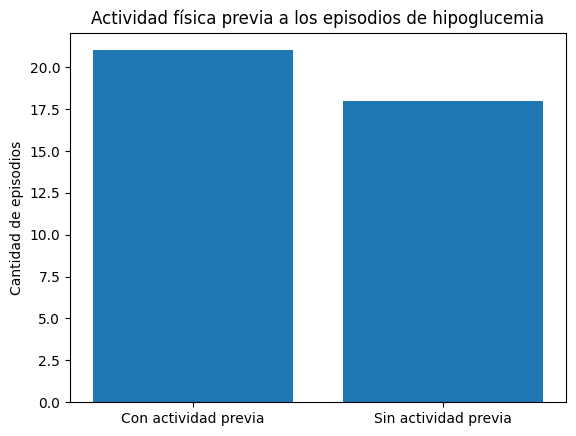

In [14]:
import matplotlib.pyplot as plt

categorias = ["Con actividad previa", "Sin actividad previa"]
cantidades = [episodios_con_actividad, episodios_sin_actividad]

plt.bar(categorias, cantidades)

plt.title("Actividad física previa a los episodios de hipoglucemia")
plt.ylabel("Cantidad de episodios")

plt.show()

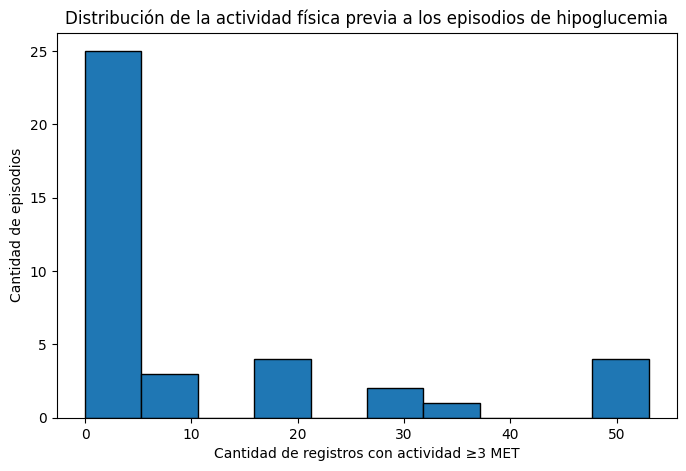

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    actividad_previa["Registros_>=3_MET"],
    bins=10,
    edgecolor="black"
)

plt.xlabel("Cantidad de registros con actividad ≥3 MET")
plt.ylabel("Cantidad de episodios")
plt.title("Distribución de la actividad física previa a los episodios de hipoglucemia")

plt.show()

### Interpretación de los gráficos

De los 39 episodios analizados, 21 presentaron al menos un registro de actividad de intensidad moderada o superior (≥3 MET) durante la hora previa, mientras que 18 no presentaron este nivel de actividad.

El histograma permite observar que la cantidad de registros de actividad previa no fue igual en todos los episodios: algunos presentaron poca o ninguna actividad moderada, mientras que otros mostraron una mayor cantidad de registros con ≥3 MET.

Estos resultados muestran que existe variabilidad en la actividad física previa a los episodios de hipoglucemia. Sin embargo, este análisis es exploratorio y no permite establecer una relación causal.

## Preparación de los datos para Machine Learning

Para desarrollar el modelo de clasificación se definirán dos tipos de situaciones:

- **1 = Con hipoglucemia:** situaciones en las que posteriormente se produce un episodio de hipoglucemia.
- **0 = Sin hipoglucemia:** situaciones en las que posteriormente no se produce un episodio de hipoglucemia.

El objetivo será analizar si la información disponible antes de cada situación, especialmente la glucosa y la actividad física, permite diferenciar ambos grupos.

In [16]:
participantes_sin_episodios = resumen_episodios[
    resumen_episodios["Episodios"] == 0
]

participantes_sin_episodios

,Participante,Episodios
2,CGMacros-012,0
6,CGMacros-035,0
10,CGMacros-042,0
11,CGMacros-046,0
12,CGMacros-047,0


### Preparación de los casos con hipoglucemia

Para cada episodio de hipoglucemia identificado se analizaron los **60 minutos anteriores a su inicio**.

De este período se obtuvieron dos variables:

- **Glucosa_media:** promedio de glucosa durante los 60 minutos previos.
- **MET_medio:** promedio de actividad física durante los 60 minutos previos.

Cada una de estas situaciones fue identificada con **Hipoglucemia = 1**, indicando que posteriormente se produjo un episodio de hipoglucemia.

De esta manera, el modelo utilizará información anterior al episodio y no datos obtenidos una vez iniciada la hipoglucemia.

In [17]:
casos_hipoglucemia = []

for _, episodio in episodios_detectados.iterrows():

    participante = episodio["Participante"]
    archivo = ruta_datos / f"{participante}.csv"
    datos = pd.read_csv(archivo)

    # Solo utilizamos archivos que tienen METs
    if "METs" not in datos.columns:
        continue

    datos["Timestamp"] = pd.to_datetime(datos["Timestamp"])
    datos["METs_reales"] = datos["METs"] / 10

    inicio = episodio["Inicio"]
    hora_antes = inicio - pd.Timedelta(hours=1)

    periodo = datos[
        (datos["Timestamp"] >= hora_antes) &
        (datos["Timestamp"] < inicio)
    ]

    casos_hipoglucemia.append({
        "Participante": participante,
        "Glucosa_media": periodo["Libre GL"].mean(),
        "MET_medio": periodo["METs_reales"].mean(),
        "Hipoglucemia": 1
    })

casos_hipoglucemia = pd.DataFrame(casos_hipoglucemia)

casos_hipoglucemia.head()

,Participante,Glucosa_media,MET_medio,Hipoglucemia
0,CGMacros-003,76.736667,1.280000,1
1,CGMacros-003,76.840000,1.116667,1
2,CGMacros-003,99.233333,5.983333,1
3,CGMacros-003,89.761111,3.081667,1
4,CGMacros-005,82.624444,1.636667,1


### Preparación de casos sin hipoglucemia en los mismos participantes

Se buscarán períodos sin hipoglucemia en los participantes que presentaron episodios, utilizando los registros de glucosa y actividad física.

Para construir los casos negativos se considerarán períodos de 60 minutos de observación, seguidos de otros 60 minutos sin aparición de hipoglucemia.

Esto permitirá comparar situaciones con y sin hipoglucemia dentro de los mismos participantes.

### Selección y verificación de los participantes

Para construir los casos sin hipoglucemia se utilizarán los mismos participantes que presentaron episodios de hipoglucemia. De esta manera, podremos comparar situaciones con y sin hipoglucemia dentro del mismo grupo de participantes.

Primero identificamos los participantes que presentaron episodios. Luego verificamos la frecuencia temporal de sus registros, ya que necesitamos conocer el intervalo entre las mediciones para construir correctamente los períodos de observación de 60 minutos.

In [18]:
participantes_positivos = casos_hipoglucemia["Participante"].unique()

print("Participantes disponibles:")
print(participantes_positivos)

print("\nCantidad:", len(participantes_positivos))

Participantes disponibles:
['CGMacros-003' 'CGMacros-005' 'CGMacros-014' 'CGMacros-028'
 'CGMacros-030' 'CGMacros-036' 'CGMacros-039' 'CGMacros-049']

Cantidad: 8


In [19]:
for participante in participantes_positivos:
    datos = datos_participantes[participante].copy()

    datos["Timestamp"] = pd.to_datetime(datos["Timestamp"])
    datos = datos.sort_values("Timestamp")

    intervalos = datos["Timestamp"].diff()

    print(
        participante,
        "Intervalo más frecuente:",
        intervalos.mode().iloc[0]
    )

CGMacros-003 Intervalo más frecuente: 0 days 00:01:00
CGMacros-005 Intervalo más frecuente: 0 days 00:01:00
CGMacros-014 Intervalo más frecuente: 0 days 00:01:00
CGMacros-028 Intervalo más frecuente: 0 days 00:01:00
CGMacros-030 Intervalo más frecuente: 0 days 00:01:00
CGMacros-036 Intervalo más frecuente: 0 days 00:01:00
CGMacros-039 Intervalo más frecuente: 0 days 00:01:00
CGMacros-049 Intervalo más frecuente: 0 days 00:01:00


### Resultado de la verificación temporal

En los 8 participantes seleccionados, el intervalo más frecuente entre los registros consecutivos es de **1 minuto**.

Esto confirma que los datos presentan una frecuencia temporal adecuada para construir períodos de observación de **60 minutos** antes de evaluar la aparición o no de hipoglucemia.

In [20]:
for participante in participantes_positivos:
    datos = datos_participantes[participante].copy()

    datos["Timestamp"] = pd.to_datetime(datos["Timestamp"])
    datos = datos.sort_values("Timestamp")

    intervalos = datos["Timestamp"].diff()

    interrupciones = (
        intervalos > pd.Timedelta(minutes=1)
    ).sum()

    print(participante, ":", interrupciones, "interrupciones")

CGMacros-003 : 15 interrupciones
CGMacros-005 : 0 interrupciones
CGMacros-014 : 0 interrupciones
CGMacros-028 : 0 interrupciones
CGMacros-030 : 0 interrupciones
CGMacros-036 : 0 interrupciones
CGMacros-039 : 0 interrupciones
CGMacros-049 : 0 interrupciones


### Control de continuidad temporal

Aunque el intervalo más frecuente entre las mediciones es de 1 minuto, también verificamos si existen interrupciones en los registros.

La mayoría de los participantes no presentó interrupciones, mientras que CGMacros-003 presentó 15. Por este motivo, al construir los casos sin hipoglucemia se utilizarán únicamente períodos con registros continuos, evitando considerar como una ventana completa aquellos períodos en los que falten mediciones.

In [21]:
nuevos_casos_negativos = []

for participante in participantes_positivos:

    datos = datos_participantes[participante].copy()

    datos["Timestamp"] = pd.to_datetime(datos["Timestamp"])
    datos = datos.sort_values("Timestamp").reset_index(drop=True)

    if "METs" not in datos.columns:
        continue

    datos["METs_reales"] = datos["METs"] / 10

    # Ventanas de 60 minutos de observación
    # seguidas de 60 minutos de predicción

    for inicio in range(0, len(datos) - 119, 120):

        ventana = datos.iloc[inicio:inicio + 120]

        observacion = ventana.iloc[:60]
        futuro = ventana.iloc[60:]

        # Comprobar continuidad temporal
        continuo = (
            ventana["Timestamp"].diff().iloc[1:]
            == pd.Timedelta(minutes=1)
        ).all()

        if not continuo:
            continue

        # Excluir ventanas con datos faltantes
        if ventana[["Libre GL", "METs_reales"]].isna().any().any():
            continue

        # Sin hipoglucemia durante ambas horas
        if (ventana["Libre GL"] < 70).any():
            continue

        nuevos_casos_negativos.append({
            "Participante": participante,
            "Glucosa_media": observacion["Libre GL"].mean(),
            "MET_medio": observacion["METs_reales"].mean(),
            "Hipoglucemia": 0
        })

nuevos_casos_negativos = pd.DataFrame(nuevos_casos_negativos)

print("Nuevos casos sin hipoglucemia:",
      len(nuevos_casos_negativos))

print("\nCasos por participante:")

print(
    nuevos_casos_negativos.groupby("Participante").size()
)

Nuevos casos sin hipoglucemia: 950

Casos por participante:
Participante
CGMacros-003    114
CGMacros-005    115
CGMacros-014    125
CGMacros-028    124
CGMacros-030    114
CGMacros-036     99
CGMacros-039    139
CGMacros-049    120
dtype: int64


### Resultado de la construcción de casos sin hipoglucemia

Aplicando estos criterios se obtuvieron **950 casos sin hipoglucemia** correspondientes a los mismos participantes que presentaron episodios.

Cada caso utiliza los primeros **60 minutos como período de observación**, del cual se obtienen la glucosa media y el MET medio, y verifica posteriormente un período de **60 minutos sin hipoglucemia**.

Estos casos constituirán la clase **Hipoglucemia = 0** para el modelo de Machine Learning.

In [22]:
print("Casos positivos:", len(casos_hipoglucemia))
print("Casos negativos:", len(nuevos_casos_negativos))

print("\nParticipantes en ambas clases:")

print(
    set(casos_hipoglucemia["Participante"])
    &
    set(nuevos_casos_negativos["Participante"])
)

Casos positivos: 39
Casos negativos: 950

Participantes en ambas clases:
{'CGMacros-036', 'CGMacros-028', 'CGMacros-005', 'CGMacros-030', 'CGMacros-039', 'CGMacros-014', 'CGMacros-003', 'CGMacros-049'}


### Preparación del conjunto de datos para la validación

Se obtuvieron **39 casos con hipoglucemia** y **950 casos sin hipoglucemia**, correspondientes a los mismos 8 participantes.

Para evaluar el modelo, los datos se separarán en conjuntos de entrenamiento y prueba **por participante**, evitando que los registros de una misma persona aparezcan en ambos conjuntos.

De esta manera, la evaluación permitirá comprobar cómo se comporta el modelo frente a participantes cuyos registros no fueron utilizados durante el entrenamiento.renamiento y prueba, evitando que los registros de un mismo participante aparezcan en ambos grupos.

El objetivo es comprobar si el modelo puede identificar situaciones de riesgo de hipoglucemia en participantes cuyos registros no utilizó durante el entrenamiento.

In [23]:
datos_ml_nuevo = pd.concat(
    [casos_hipoglucemia, nuevos_casos_negativos],
    ignore_index=True
)

print("Total de casos:", len(datos_ml_nuevo))

print("\nDistribución de las clases:")
print(datos_ml_nuevo["Hipoglucemia"].value_counts())

print("\nParticipantes:", datos_ml_nuevo["Participante"].nunique())

Total de casos: 989

Distribución de las clases:
Hipoglucemia
0    950
1     39
Name: count, dtype: int64

Participantes: 8


### Separación de los datos por participante

Para evaluar la capacidad de generalización del modelo, se separarán los participantes entre entrenamiento y prueba.

De esta manera, el modelo será evaluado con registros de personas que no participaron en su entrenamiento, evitando compartir información de un mismo participante entre ambos conjuntos.

In [24]:
from sklearn.model_selection import GroupShuffleSplit

separador = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

indice_train, indice_test = next(
    separador.split(
        datos_ml_nuevo,
        groups=datos_ml_nuevo["Participante"]
    )
)

train_nuevo = datos_ml_nuevo.iloc[indice_train]
test_nuevo = datos_ml_nuevo.iloc[indice_test]

print("Participantes en entrenamiento:")
print(train_nuevo["Participante"].unique())

print("\nParticipantes en prueba:")
print(test_nuevo["Participante"].unique())

Participantes en entrenamiento:
['CGMacros-003' 'CGMacros-014' 'CGMacros-028' 'CGMacros-030'
 'CGMacros-039' 'CGMacros-049']

Participantes en prueba:
['CGMacros-005' 'CGMacros-036']


In [25]:
print("Clases en entrenamiento:")
print(train_nuevo["Hipoglucemia"].value_counts())

print("\nClases en prueba:")
print(test_nuevo["Hipoglucemia"].value_counts())

Clases en entrenamiento:
Hipoglucemia
0    736
1     16
Name: count, dtype: int64

Clases en prueba:
Hipoglucemia
0    214
1     23
Name: count, dtype: int64


### Balance de las clases en entrenamiento

El conjunto de entrenamiento contiene 16 casos con hipoglucemia y 736 sin hipoglucemia.

Para evitar que el modelo favorezca la clase mayoritaria, se seleccionarán aleatoriamente 16 casos sin hipoglucemia.

El conjunto de prueba permanecerá sin modificaciones para evaluar el modelo con datos de participantes no utilizados durante el entrenamiento.

In [26]:
# Separamos las dos clases del entrenamiento

positivos_train = train_nuevo[
    train_nuevo["Hipoglucemia"] == 1
]

negativos_train = train_nuevo[
    train_nuevo["Hipoglucemia"] == 0
]

# Seleccionamos 16 casos negativos

negativos_balanceados = negativos_train.sample(
    n=len(positivos_train),
    random_state=42
)

# Unimos ambas clases

train_balanceado = pd.concat(
    [positivos_train, negativos_balanceados],
    ignore_index=True
)

print("Clases en entrenamiento balanceado:")
print(train_balanceado["Hipoglucemia"].value_counts())

print("\nCasos de prueba sin modificar:", len(test_nuevo))

Clases en entrenamiento balanceado:
Hipoglucemia
1    16
0    16
Name: count, dtype: int64

Casos de prueba sin modificar: 237


### Conjunto de entrenamiento y prueba

El conjunto de entrenamiento quedó balanceado con **32 casos: 16 con hipoglucemia y 16 sin hipoglucemia**.

El conjunto de prueba se mantuvo sin modificar, con **237 casos**, ya que su función es evaluar el comportamiento del modelo con los participantes que no fueron utilizados durante el entrenamiento.

El balance se realizó únicamente sobre los datos de entrenamiento para no alterar la evaluación final del modelo.

In [27]:
variables = ["Glucosa_media", "MET_medio"]

X_train = train_balanceado[variables]
y_train = train_balanceado["Hipoglucemia"]

X_test = test_nuevo[variables]
y_test = test_nuevo["Hipoglucemia"]

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (32, 2)
Prueba: (237, 2)


### Estandarización de las variables

Antes de entrenar el modelo se aplicó `StandardScaler` a las variables predictoras para colocarlas en una escala comparable.

El ajuste del escalado se realizó utilizando únicamente los datos de entrenamiento y posteriormente se aplicó la misma transformación a los datos de prueba.

In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Variables escaladas correctamente")

Variables escaladas correctamente


### Entrenamiento del modelo

Se utilizará Regresión Logística para clasificar las situaciones según la aparición o no de hipoglucemia.

El modelo aprenderá a partir de la glucosa media y la actividad física media (METs) registradas durante la hora anterior.

Posteriormente, se evaluará con los participantes reservados para prueba.

In [29]:
from sklearn.linear_model import LogisticRegression

modelo_nuevo = LogisticRegression(
    random_state=42,
    max_iter=1000
)

modelo_nuevo.fit(X_train_scaled, y_train)

print("Modelo entrenado correctamente")

Modelo entrenado correctamente


### Evaluación del modelo con participantes no utilizados en el entrenamiento

Se evaluará el modelo con los 237 casos reservados para prueba, correspondientes a dos participantes diferentes de los utilizados durante el entrenamiento.

Se analizará su capacidad para identificar correctamente los casos con y sin hipoglucemia.

In [30]:
print("Valores faltantes en entrenamiento:")
print(X_train.isna().sum())

print("\nValores faltantes en prueba:")
print(X_test.isna().sum())

Valores faltantes en entrenamiento:
Glucosa_media    0
MET_medio        0
dtype: int64

Valores faltantes en prueba:
Glucosa_media    0
MET_medio        2
dtype: int64


### Tratamiento de valores faltantes en el conjunto de prueba

Se encontraron **2 valores faltantes en la variable MET_medio** del conjunto de prueba.

Para conservar estos casos, los valores faltantes se reemplazaron por la **mediana de MET_medio calculada únicamente con los datos de entrenamiento**.

De esta manera, no se utiliza información del conjunto de prueba para calcular el valor de reemplazo.

In [31]:
# Calculamos la mediana de METs en entrenamiento
mediana_met = X_train["MET_medio"].median()

# Completamos los valores faltantes en prueba
X_test = X_test.copy()

X_test["MET_medio"] = X_test["MET_medio"].fillna(
    mediana_met
)

# Aplicamos nuevamente la estandarización
X_test_scaled = scaler.transform(X_test)

print("Valores faltantes restantes:")
print(X_test.isna().sum())

Valores faltantes restantes:
Glucosa_media    0
MET_medio        0
dtype: int64


## Resultados y evaluación del modelo

In [32]:
from sklearn.metrics import classification_report, confusion_matrix

predicciones_nuevas = modelo_nuevo.predict(X_test_scaled)

print("Matriz de confusión:")
print(confusion_matrix(y_test, predicciones_nuevas))

print("\nInforme de clasificación:")
print(classification_report(y_test, predicciones_nuevas))

Matriz de confusión:
[[115  99]
 [  0  23]]

Informe de clasificación:
              precision    recall  f1-score   support

           0       1.00      0.54      0.70       214
           1       0.19      1.00      0.32        23

    accuracy                           0.58       237
   macro avg       0.59      0.77      0.51       237
weighted avg       0.92      0.58      0.66       237



### Interpretación de los resultados del modelo

La matriz de confusión muestra los siguientes resultados:

- **115 casos sin hipoglucemia** fueron clasificados correctamente.
- **99 casos sin hipoglucemia** fueron clasificados erróneamente como hipoglucemia.
- **23 casos con hipoglucemia** fueron identificados correctamente.
- **0 casos con hipoglucemia** quedaron sin detectar.

El modelo alcanzó una **sensibilidad (recall) del 100 % para la hipoglucemia**, ya que identificó los 23 casos presentes en el conjunto de prueba.

Sin embargo, la **precisión para hipoglucemia fue del 19 %**, debido a la elevada cantidad de falsas alarmas. El **F1-score para hipoglucemia fue de 0,32** y la **exactitud global del modelo fue del 58 %**.

Por lo tanto, el modelo presenta una alta capacidad para detectar los casos de hipoglucemia, pero todavía tiene dificultades para diferenciar correctamente las situaciones que no desarrollarán hipoglucemia.

### Análisis de las variables predictoras en el conjunto de prueba

Para comprender mejor el comportamiento del modelo, se analizará cómo se distribuyen las dos variables predictoras, **Glucosa_media** y **MET_medio**, entre los casos con y sin hipoglucemia del conjunto de prueba.

Las tablas siguientes presentan, para cada grupo, la cantidad de casos (`count`), el promedio (`mean`), la dispersión de los valores (`std`), el valor mínimo (`min`), los cuartiles (`25 %`, `50 %` y `75 %`) y el valor máximo (`max`).

La primera tabla analiza la **glucosa media registrada durante la hora previa**, mientras que la segunda analiza la **actividad física media expresada en MET durante ese mismo período**.

In [33]:
test_nuevo.groupby("Hipoglucemia")["Glucosa_media"].describe()

,count,mean,std,min,25%,50%,75%,max
Hipoglucemia,,,,,,,,
0,214.0,117.531931,33.439113,70.616667,93.533333,107.708333,132.558333,267.966667
1,23.0,78.800242,8.818757,64.883333,73.378333,78.500000,84.575000,96.217778


In [34]:
test_nuevo.groupby("Hipoglucemia")["MET_medio"].describe()

,count,mean,std,min,25%,50%,75%,max
Hipoglucemia,,,,,,,,
0,214.0,1.677593,0.933939,1.0,1.051250,1.443333,1.880833,7.701667
1,21.0,1.470714,0.910473,1.0,1.001667,1.070000,1.636667,5.010000


In [35]:
coeficientes = pd.DataFrame({
    "Variable": ["Glucosa_media", "MET_medio"],
    "Coeficiente": modelo_nuevo.coef_[0]
})

coeficientes

,Variable,Coeficiente
0,Glucosa_media,-1.644192
1,MET_medio,0.175241


### Interpretación de las variables predictoras


El modelo asignó un coeficiente negativo a la glucosa media (-1,644) y positivo al MET medio (0,175).


.



En los datos analizados, la **glucosa fue la variable que mostró la relación más clara con la aparición posterior de hipoglucemia**. Los casos que posteriormente presentaron hipoglucemia tenían, en promedio, valores de glucosa más bajos durante la hora previa.

La **actividad física, medida mediante METs, también aportó información al modelo**, pero su influencia fue considerablemente menor que la de la glucosa. El modelo mostró que, al considerar conjuntamente ambas variables, una mayor intensidad de actividad física se relacionó con un ligero aumento de la probabilidad estimada de hipoglucemia.

Por lo tanto, en este dataset, la **glucosa previa fue el principal indicador del riesgo**, mientras que la actividad física tuvo un aporte menor. Estos resultados muestran asociaciones presentes en los datos y no permiten afirmar que el ejercicio sea la causa de la hipoglucemia.

### Comprobación de posible sobreajuste

In [36]:
from sklearn.metrics import accuracy_score

# Predicciones en entrenamiento
pred_train = modelo_nuevo.predict(X_train_scaled)

# Predicciones en prueba
pred_test = modelo_nuevo.predict(X_test_scaled)

# Exactitud en ambos conjuntos
accuracy_train = accuracy_score(y_train, pred_train)
accuracy_test = accuracy_score(y_test, pred_test)

print("Accuracy en entrenamiento:", round(accuracy_train, 2))
print("Accuracy en prueba:", round(accuracy_test, 2))

Accuracy en entrenamiento: 0.78
Accuracy en prueba: 0.58


### Evaluación del posible sobreajuste

Durante el desarrollo del modelo se tomaron medidas para **reducir al mínimo posible el riesgo de sobreajuste**. En particular, los datos se separaron por participante, de manera que las personas utilizadas para evaluar el modelo no fueran las mismas que participaron en su entrenamiento.

Además, el balanceo de las clases se realizó únicamente sobre el conjunto de entrenamiento, mientras que el conjunto de prueba se mantuvo sin modificar. De esta manera, la evaluación se realizó sobre datos independientes y más cercanos a las condiciones reales.

El modelo obtuvo una exactitud del **78 % en entrenamiento** y del **58 % en prueba**. Esta disminución muestra que el modelo tiene una capacidad de generalización limitada y que no puede descartarse cierto grado de sobreajuste, aunque se trabajó metodológicamente para reducirlo.

Hay otro detalle muy importante: con tan pocos ejemplos de entrenamiento y pocos participantes, una diferencia entre 78 % y 58 % también puede deberse a que el modelo tuvo poca información para aprender, no exclusivamente al sobreajuste.

# Conclusión general

El desarrollo de este proyecto permitió construir un modelo de Machine Learning orientado a la **predicción del riesgo de hipoglucemia**, utilizando información de glucosa y actividad física registrada durante la hora previa.

A partir de los datos de CGMacros fue posible identificar episodios de hipoglucemia, estudiar la actividad física mediante METs y transformar los registros originales en un conjunto de datos adecuado para un problema de clasificación binaria.

Uno de los principales resultados fue que el modelo de Regresión Logística logró **identificar correctamente los 23 casos de hipoglucemia presentes en el conjunto de prueba**, alcanzando una sensibilidad del **100 %** para esta clase. Además, el análisis de los coeficientes mostró que una menor glucosa media previa se relacionó con una mayor probabilidad estimada de hipoglucemia y que la actividad física, representada por el MET medio, también aportó información al modelo, aunque con menor influencia.

Para realizar una evaluación más rigurosa, el entrenamiento y la prueba se separaron por participante, evitando que una misma persona estuviera presente en ambos conjuntos. También se balancearon únicamente los datos de entrenamiento y se mantuvieron sin modificar los datos de prueba. Estas decisiones permitieron reducir el riesgo de fuga de información y trabajar para minimizar el sobreajuste.

En conjunto, el proyecto permitió comprobar que es posible utilizar los registros continuos de glucosa y actividad física para **identificar patrones asociados al riesgo de hipoglucemia** y desarrollar una primera aproximación predictiva basada en datos.